# Elastic Net: linear ML slice

**Question:** does a regularised linear model (Elastic Net) using all 10 features forecast next week's volatility better than HAR?

This notebook uses only the 2,452 training rows (30 Mar 2005 to 23 Dec 2014) of `data/processed/model_table.csv`, built by `Main_Notebook.ipynb`. The 717 test rows (2015 to 2017) are never loaded here; the single test run will be added later, behind `RUN_TEST` in section 1.

The sections are described below:

- Section 1: sets up the notebook and loads the data;
- Section 2: explores features 4 and 6 to 8;
- Section 3: checks the correlations between all 10 features
- Section 4: sets up the cross-validation;
- Section 5: chooses alpha and l1_ratio with a grid search
- Section 6: scores the chosen settings on each fold
- Section 7: fixes the chosen settings for the rest of the project.

## 1. Setup and data

Imports, the repo root as working directory, one plot style, and the `RUN_TEST` lock for the later test run.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler

# Work from the repo root, like the main notebook (this notebook lives in slices/linear_ml/)
if os.path.basename(os.getcwd()) == "linear_ml":
    os.chdir("../..")
sys.path.append(os.getcwd())
from src.foundation.evaluate import evaluate

sns.set_theme(style="whitegrid", font_scale=1.1)
os.makedirs("results/figures", exist_ok=True)

RUN_TEST = False   # switch to True only on the test-run call, after the settings are frozen

### 1.1 Load the training rows

Same table and training rows as every other model, so the scores are comparable.

In [2]:
# Read data
model_table = pd.read_csv("data/processed/model_table.csv", parse_dates=['date'])

train = model_table[model_table["split"] == "train"].reset_index(drop=True)

FEATURES = ["f1", "f2", "f3", "f4", "f5", "f6", "f7", "f8", "f9", "f10"]

print("Training rows:", len(train))
print("First date:", train["date"].min().date())
print("Last date:", train["date"].max().date())

Training rows: 2452
First date: 2005-03-30
Last date: 2014-12-23


## 2. Exploration of features 4, 6, 7 and 8

**Goal:** understand the four features one at a time before any model uses them.

The features are:
- f4: log VIX;
- f6: log volatility of the bond ETF (TLT) over 22 days;
- f7: log of bank ETF (XLF) volatility divided by SPY volatility, over 22 days;
- f8: the bond ETF's 22-day log return.

For each one we look at its typical value, spread, extremes and whether it has a long tail.

### 2.1 Summary Statistics

One table giving each feature's centre (mean, median), spread (standard deviation), extremes (min, max) and shape (skew).

The count proves that there are no missing values in the training rows.

In [3]:
# One row per feature: count, centre, spread, extremes and shape. Round to 3 decimals for display.
train[["f4", "f6", "f7", "f8"]].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T.round(3)

,count,mean,median,std,min,max,skew
f4,2452.0,2.917,2.848,0.399,2.292,4.393,0.925
f6,2452.0,-3.307,-3.344,0.380,-4.475,-2.232,0.270
f7,2452.0,0.360,0.311,0.250,-0.236,1.332,1.030
f8,2452.0,0.004,0.003,0.039,-0.153,0.245,0.732


### 2.2 Histograms

The table gives the numbers, while a histogram shows the shape. We look at where most days sit, and whether a few crisis days (such as 2008) form a long tail.

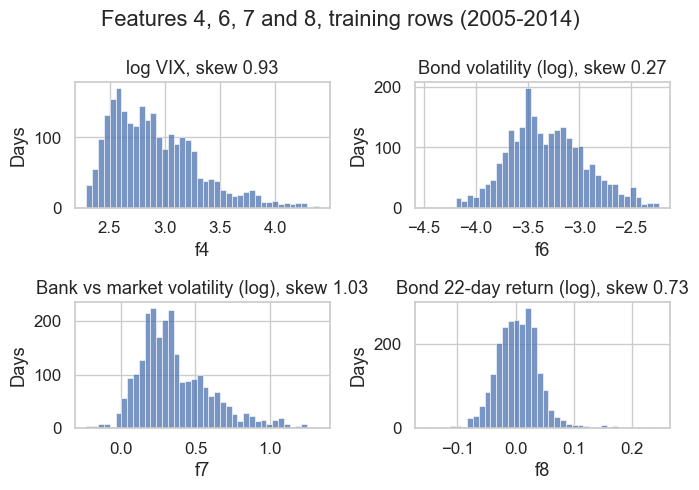

In [4]:
NAMES = {"f4": "log VIX",
         "f6": "Bond volatility (log)",
         "f7": "Bank vs market volatility (log)",
         "f8": "Bond 22-day return (log)"}

# Draw the histograms, one per feature
fig, axes = plt.subplots(2, 2, figsize=(7, 5))
for ax, col in zip(axes.flat, NAMES):
    sns.histplot(train[col], bins=40, ax=ax)
    ax.set_title(f"{NAMES[col]}, skew {train[col].skew():.2f}")
    ax.set_xlabel(col)
    ax.set_ylabel("Days")

fig.suptitle("Features 4, 6, 7 and 8, training rows (2005-2014)")

# Save histograms image under results folder
plt.tight_layout()
plt.savefig("results/figures/eda_hist_f4_f6_f7_f8.png", dpi=200)
plt.show()

### 2.3 Where the tails come from

For each feature with a clear right tail (f4, f7 and f8; f6 is roughly symmetric), we take its 20 highest training days and count how many fall in each year.

In [5]:
# Where do the right tails come from? Years of each feature's 20 highest days (training rows)
for col in ["f4", "f7", "f8"]:
    top = train.nlargest(20, col)
    print(col, top["date"].dt.year.value_counts().sort_index().to_dict())

f4 {2008: 20}
f7 {2008: 18, 2009: 2}
f8 {2008: 17, 2011: 3}


### 2.4 Result

Our conclusions so far are below:
- All four features are complete on the 2,452 training rows (no missing values). 
- f6 (bond volatility) is roughly symmetric (skew 0.27). The other three have a right tail: 
    - f7 (bank vs market volatility, skew 1.03) reaches 1.332.
    - f4 (log VIX, skew 0.93) reaches 4.393.
    - f8 (bond 22-day return, skew 0.73) is symmetric around 0 apart from a few large positive returns up to 0.245.
- The largest values of f4, f7, and f8 come mostly from 2008, so the tails come from a small number of stressed periods. f4, f6 and f7 are already logs, and the remaining skew is moderate, so we apply no further transform.


## 3. Correlations between all 10 features

Checks whether some features carry the same information, since strongly correlated features make plain regression coefficients unstable.

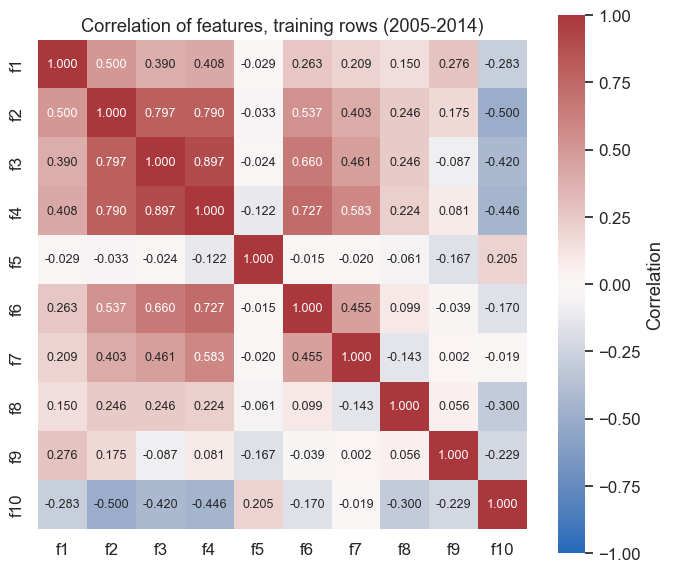

f3 vs f4 (log 22-day volatility vs log VIX): 0.897
f4  f3    0.897
f3  f2    0.797
f4  f2    0.790
f6  f4    0.727
dtype: float64


In [6]:
# Correlation of every pair of features of the training rows only.
corr = train[FEATURES].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="vlag",
            vmin=-1, vmax=1, center=0, square=True,
            annot_kws={"size": 9}, cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Correlation of features, training rows (2005-2014)")
plt.tight_layout()
plt.savefig("results/figures/eda_corr_heatmap.png", dpi=200)
plt.show()

# f3 is past volatility and the VIX is expected volatility, so we expect them to be correlated.
print(f"f3 vs f4 (log 22-day volatility vs log VIX): {corr.loc['f3', 'f4']:.3f}")

# Every other strongly correlated pair (|r| >= 0.7), strongest first
pairs = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack()
print(pairs[pairs.abs() >= 0.7].sort_values(key=abs, ascending=False).round(3))


### 3.1 Result

Four pairs have |r| >= 0.7 on the training rows. Three form one group of SPY volatility measures: f4 (log VIX) with f3 (last 22 days), 0.897; f3 with f2 (last 5 days), 0.797; f4 with f2, 0.790. Past volatility and the volatility the market expects move closely together. The fourth pair is cross-asset: bond volatility (f6) with the VIX (f4), 0.727.

f2, f3 and f4 are correlated (r up to 0.897), so plain regression coefficients would be unstable, which is one reason to use regularisation. Cross-validation picks the L1/L2 mix in section 5.

Whether the extra features, such as f4 and f6, add information beyond HAR's features (f1-f3) is tested by comparing the model with HAR.

## 4. Cross-validation setup

The same 5 time-ordered folds as every other model: each fold fits on the earlier years and scores on the next block, with a 5-row gap because the target covers the next 5 trading days.

In [7]:
X_train, y_train = train[FEATURES], train["y"]

# Same cross-validation (CV) as every model: 5 folds inside the training years, 5-row gap
tscv = TimeSeriesSplit(n_splits=5, gap=5)
for k, (fit_idx, val_idx) in enumerate(tscv.split(train), start=1):
    print(f"Fold {k}: fit {train['date'][fit_idx[0]].date()} to {train['date'][fit_idx[-1]].date()}, "
          f"score {train['date'][val_idx[0]].date()} to {train['date'][val_idx[-1]].date()}")

Fold 1: fit 2005-03-30 to 2006-11-06, score 2006-11-14 to 2008-06-30
Fold 2: fit 2005-03-30 to 2008-06-23, score 2008-07-01 to 2010-02-11
Fold 3: fit 2005-03-30 to 2010-02-04, score 2010-02-12 to 2011-09-26
Fold 4: fit 2005-03-30 to 2011-09-19, score 2011-09-27 to 2013-05-13
Fold 5: fit 2005-03-30 to 2013-05-06, score 2013-05-14 to 2014-12-23


### 4.1 The model and a helper to score it on the folds

Scaling goes inside the pipeline, so each fold is scaled on its own fitted rows (the penalty needs all features on one scale). `cv_scores()` returns MAE, RMSE and R^2 for each fold, with the shared `evaluate()`.

In [8]:
# Scaler + Elastic Net in one pipeline, so each fold's scaler learns from that fold's fitted rows only.
def make_enet(alpha, l1_ratio):
    return Pipeline([
        ("scale", StandardScaler()),
        ("enet", ElasticNet(alpha=alpha, l1_ratio=l1_ratio)),
    ])

# Fit on each fold's earlier years, score on the next block. One row per fold.
def cv_scores(model):
    rows = []
    for fit_idx, val_idx in tscv.split(train):
        model.fit(X_train.loc[fit_idx], y_train[fit_idx])
        y_pred = model.predict(X_train.loc[val_idx])
        rows.append(evaluate(y_train[val_idx], y_pred))
    return pd.DataFrame(rows, index=range(1, 6)).rename_axis("fold")

## 5. Grid search over alpha and l1_ratio

Tuning `alpha` (penalty strength) and `l1_ratio` (L1 vs L2 mix), keeping the pair with the lowest average RMSE over the 5 folds.

### 5.1 Where the alpha grid should end

`alpha_max` is the smallest alpha that sets every coefficient to 0 (the model then just predicts the average), so the grid doesn't need to go beyond it.

In [9]:
# Smallest alpha that sets every coefficient to 0, for l1_ratio = 1 (Lasso)
Xs = StandardScaler().fit_transform(X_train)
alpha_max = np.abs(Xs.T @ (y_train - y_train.mean())).max() / len(y_train)
print(f"alpha_max (l1_ratio = 1): {alpha_max:.4f}")

# Double-checking: just above alpha_max we expect the fitted model to keep no feature
check = make_enet(alpha_max * 1.01, 1.0).fit(X_train, y_train)
print("Non-zero coefficients just above alpha_max:", (check.named_steps["enet"].coef_ != 0).sum())

alpha_max (l1_ratio = 1): 0.4914
Non-zero coefficients just above alpha_max: 0


### 5.2 Grid search

`alpha` in powers of ten, from 0.0001 up to the first one above `alpha_max`; `l1_ratio` in 0.1, 0.5, 0.9 and 1.0.

In [10]:
# alpha: powers of ten from 0.0001 up to the first one above alpha_max (section 5.1)
alphas = [10.0 ** k for k in range(-4, int(np.ceil(np.log10(alpha_max))) + 1)]
param_grid = {"enet__alpha": alphas,
              "enet__l1_ratio": [0.1, 0.5, 0.9, 1.0]}
print("alpha values:", alphas)

grid = GridSearchCV(make_enet(1.0, 0.5), param_grid,
                    cv=tscv, scoring="neg_root_mean_squared_error")
grid.fit(X_train, y_train)

# scikit-learn reports negative RMSE; flip the sign so lower = better
results = pd.DataFrame(grid.cv_results_)
results["cv_rmse"] = -results["mean_test_score"]
print("Best settings:", grid.best_params_, f"CV RMSE {-grid.best_score_:.3f}")
results[["param_enet__alpha", "param_enet__l1_ratio", "cv_rmse"]].sort_values("cv_rmse").round(3)

alpha values: [0.0001, 0.001, 0.01, 0.1, 1.0]


Best settings: {'enet__alpha': 0.01, 'enet__l1_ratio': 1.0} CV RMSE 0.437


,param_enet__alpha,param_enet__l1_ratio,cv_rmse
11,0.010,1.0,0.437
10,0.010,0.9,0.437
9,0.010,0.5,0.439
12,0.100,0.1,0.440
8,0.010,0.1,0.443
7,0.001,1.0,0.443
6,0.001,0.9,0.443
5,0.001,0.5,0.444
4,0.001,0.1,0.444
3,0.000,1.0,0.445


### 5.3 Edge-of-grid check

Checks whether either best value sits at the edge of the grid.

In [11]:
best = grid.best_params_
for name, values in param_grid.items():
    value = best[name]
    if value == min(values):
        where = "smallest value in the grid"
    elif value == max(values):
        where = "largest value in the grid"
    else:
        where = "inside the grid"
    print(f"{name}: best {value} ({where})")

enet__alpha: best 0.01 (inside the grid)
enet__l1_ratio: best 1.0 (largest value in the grid)


### 5.4 Result

Best settings: `alpha` = 0.01 and `l1_ratio` = 1.0, with a CV RMSE of 0.437. `alpha` is inside the grid. Best `l1_ratio` is 1.0, the top of the grid, but that's pure Lasso, so there's nothing beyond it. `l1_ratio` = 0.9 gives the same 0.437 (and 0.5 gives 0.439), so L1 and the mixed penalties are practically tied. With the weakest penalty (`alpha` = 0.0001, almost plain regression), every `l1_ratio` gives 0.445, so the penalty helps only slightly.

## 6. Tuned Elastic Net on each CV fold

The chosen settings scored on each fold, with how much y varies in each scored block (`std_y`).

In [12]:
best = grid.best_params_
tuned_scores = cv_scores(make_enet(best["enet__alpha"], best["enet__l1_ratio"]))
print("Mean over the 5 folds:", tuned_scores.mean().round(3).to_dict())

# How much the target varies in each scored block (R^2 compares the errors with this)
tuned_scores["std_y"] = [y_train[val_idx].std(ddof=0) for _, val_idx in tscv.split(train)]
tuned_scores.round(3)

Mean over the 5 folds: {'MAE': 0.336, 'RMSE': 0.437, 'R2': 0.405}


,MAE,RMSE,R2,std_y
fold,,,,
1,0.346,0.451,0.353,0.560
2,0.336,0.430,0.545,0.637
3,0.346,0.461,0.428,0.610
4,0.334,0.434,0.397,0.559
5,0.320,0.408,0.301,0.488


### 6.1 Result

Average over the 5 folds: RMSE 0.437, MAE 0.336 and R^2 0.405. We expected fold 2 (Jul 2008 to Feb 2010, the crisis) to be the worst, but it has the highest R^2 (0.545) and the second-lowest RMSE (0.430), because y varies most there (std 0.637). Fold 5 is the opposite: the smallest errors (RMSE 0.408) but the lowest R^2 (0.301), because y varies least there (std 0.488).

## 7. Frozen settings

Goal: fix the two settings chosen above ins ection 5, so that nothing is tuned after this point.

The values are typed in by hand, so we ensure that later test runs dont depend on the grid search. The check below confirms they match what the grid search chose.

In [13]:
# Final settings, typed in by hand. They were chosen in section 5.
FINAL_PARAMS = {"alpha": 0.01, "l1_ratio": 1.0}

# The grid search's choice, without the "enet__" pipeline prefix
chosen = {k.removeprefix("enet__"): v for k, v in grid.best_params_.items()}
assert FINAL_PARAMS == chosen, f"Final params {FINAL_PARAMS} differ from grid search {chosen}"
print("Frozen settings:", FINAL_PARAMS)
print("Grid search chose:", chosen)

# The two best pairs to 5 decimals, to see the real gap between l1_ratio 1.0 and 0.9
results.nsmallest(2, "cv_rmse")[["param_enet__alpha", "param_enet__l1_ratio", "cv_rmse"]].round(5)

Frozen settings: {'alpha': 0.01, 'l1_ratio': 1.0}
Grid search chose: {'alpha': 0.01, 'l1_ratio': 1.0}


,param_enet__alpha,param_enet__l1_ratio,cv_rmse
11,0.01,1.0,0.43664
10,0.01,0.9,0.43694


### 7.1 Result

The frozen settings matched the grid search. 

In CV RMSE, l1_ratio of 1.0 gives 0.43664, while 0.9 gives 0.43694, a gap of 0.0003. That makes the two penalties practically tied, so we keep the grid's choice.